In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "serif"})

from src.part1.analysis import Analysis
from src.part1.experiment import Experiment

pd.set_option("display.precision", 3)

In [2]:
Analysis.overview()

,field,n,d,groups,target,y_mean,y_sd,y_min,y_max
dataset,,,,,,,,,
concrete,civil engineering,1030,8,–,compressive strength (MPa),35.818,16.698,2.330,82.600
airfoil,aerospace acoustics,1503,5,–,sound pressure (dB),124.836,6.896,103.380,140.987
parkinsons,medicine,1260,18,42,motor UPDRS,20.948,8.115,5.138,39.511
qsar,chemistry,546,8,–,LC50 (−log mol/L),4.658,1.664,0.122,10.047


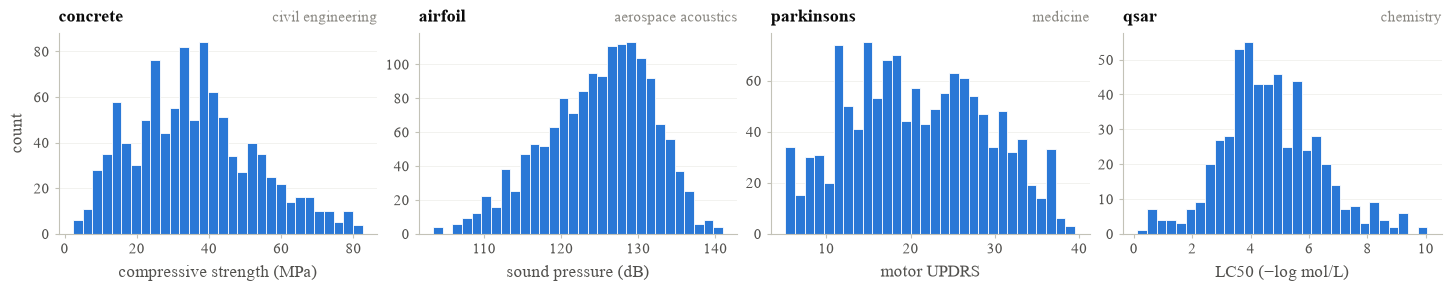

In [3]:
Analysis.plot_targets()

In [4]:
Analysis.settings()

CV folds                       5
random state                  42
Matérn ν                     1.5
restarts, iso                  5
restarts, ARD                  5
σ_f² bounds        (0.01, 100.0)
ℓ bounds          (0.01, 1000.0)
σ_n² bounds        (1e-06, 10.0)
interval level              0.95
Name: value, dtype: object

In [5]:
Experiment.run(["concrete", "airfoil", "qsar", "parkinsons"])

In [6]:
Experiment.status()

,done,expected
dataset,,
concrete,20,20
airfoil,20,20
parkinsons,20,20
qsar,20,20


In [7]:
runs, preds = Experiment.runs(), Experiment.predictions()
runs = runs.merge(Analysis.calibration_error(preds), on=Experiment.KEY, how="left")

In [8]:
Analysis.lml_order(runs)

folds with LML(ARD) < LML(iso)
dataset    kernel                                
concrete   matern                               0
           rbf                                  0
airfoil    matern                               0
           rbf                                  0
parkinsons matern                               0
           rbf                                  0
qsar       matern                               0
           rbf                                  0

In [9]:
Analysis.table(runs, ["mae", "rmse", "r2"])

mae          rmse              r2
dataset    model                                                  
concrete   SE iso         3.18 ± 0.2    4.88 ± 0.5   0.913 ± 0.019
           SE ARD       2.89 ± 0.031   4.64 ± 0.41   0.922 ± 0.012
           Matérn iso    2.88 ± 0.16   4.49 ± 0.51   0.926 ± 0.017
           Matérn ARD    2.67 ± 0.11   4.27 ± 0.49   0.934 ± 0.011
airfoil    SE iso      0.881 ± 0.086   1.34 ± 0.11  0.962 ± 0.0081
           SE ARD      0.816 ± 0.058  1.26 ± 0.088  0.967 ± 0.0044
           Matérn iso  0.732 ± 0.057    1.1 ± 0.09  0.974 ± 0.0048
           Matérn ARD  0.677 ± 0.064    1.05 ± 0.1  0.977 ± 0.0046
parkinsons SE iso        7.62 ± 0.48   9.26 ± 0.27   -0.537 ± 0.41
           SE ARD          7.4 ± 1.5    8.75 ± 1.5   -0.336 ± 0.32
           Matérn iso    7.59 ± 0.47    9.2 ± 0.23    -0.52 ± 0.42
           Matérn ARD     7.09 ± 1.2    8.44 ± 1.4   -0.236 ± 0.25
qsar       SE iso      0.835 ± 0.063   1.14 ± 0.11    0.522 ± 0.08
           SE ARD      0.822 ± 0.059   1.14 ± 0.09   0.521 ± 0.069
           Matérn iso  0.806 ± 0.056  1.12 ± 0.091    0.535 ± 0.06
           Matérn ARD  0.785 ± 0.048   1.1 ± 0.071   0.557 ± 0.047

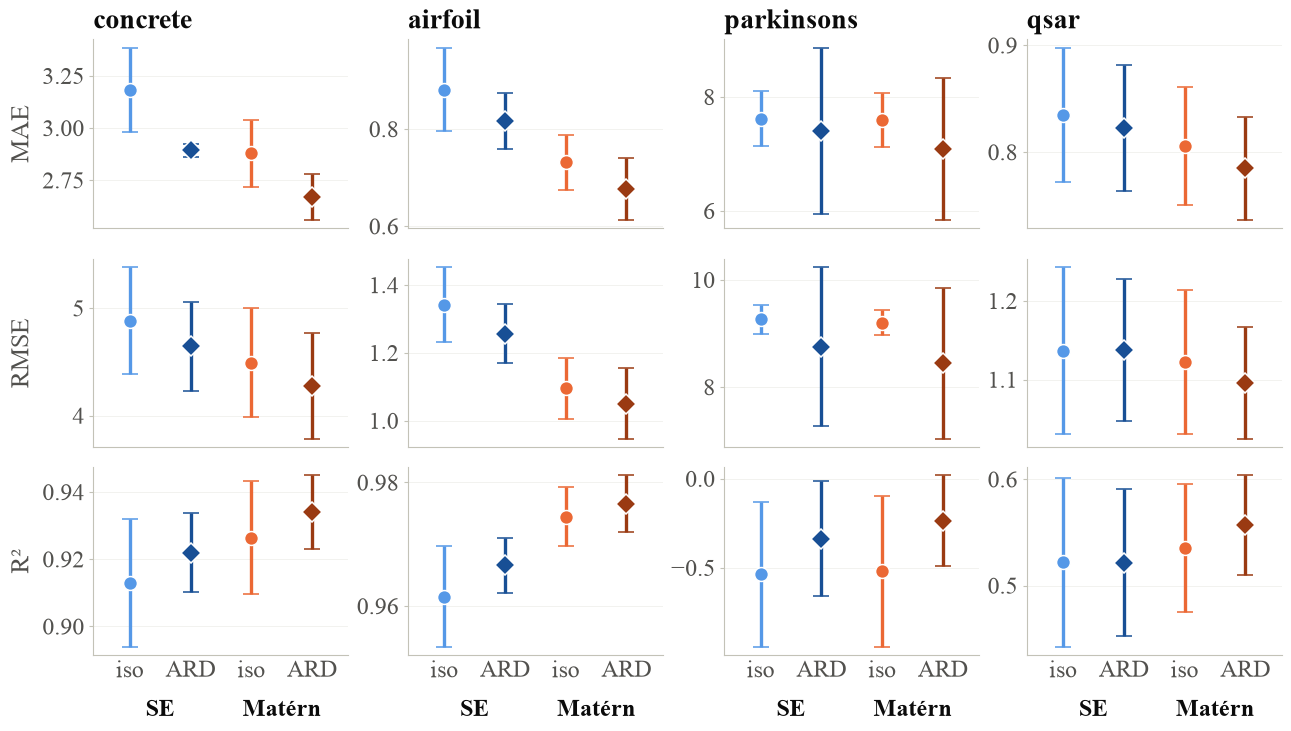

In [10]:
Analysis.plot_metrics(runs, ["mae", "rmse", "r2"])

In [11]:
Analysis.table(runs, ["nlpd", "coverage", "width"])

nlpd       coverage        width
dataset    model                                               
concrete   SE iso        2.92 ± 0.1  0.928 ± 0.021  16.2 ± 0.88
           SE ARD       2.84 ± 0.14  0.933 ± 0.015  14.9 ± 0.85
           Matérn iso   2.85 ± 0.12  0.931 ± 0.018  15.4 ± 0.73
           Matérn ARD     2.8 ± 0.2  0.933 ± 0.015   14.2 ± 1.1
airfoil    SE iso      1.64 ± 0.076  0.935 ± 0.013  4.74 ± 0.18
           SE ARD      1.58 ± 0.098  0.929 ± 0.025  4.24 ± 0.29
           Matérn iso  1.45 ± 0.055   0.94 ± 0.014  4.09 ± 0.23
           Matérn ARD  1.41 ± 0.079  0.935 ± 0.013  3.72 ± 0.27
parkinsons SE iso       4.04 ± 0.13  0.771 ± 0.031  24.1 ± 0.26
           SE ARD        4.6 ± 0.94   0.742 ± 0.16   22.8 ± 5.4
           Matérn iso   4.02 ± 0.12  0.776 ± 0.033  24.1 ± 0.39
           Matérn ARD   4.47 ± 0.96   0.772 ± 0.17   22.4 ± 4.2
qsar       SE iso       1.53 ± 0.14  0.936 ± 0.032  4.18 ± 0.19
           SE ARD       1.51 ± 0.13  0.932 ± 0.029  4.02 ± 0.14
           Matérn iso    1.5 ± 0.15   0.929 ± 0.03  4.06 ± 0.18
           Matérn ARD   1.45 ± 0.12  0.929 ± 0.036  3.91 ± 0.17

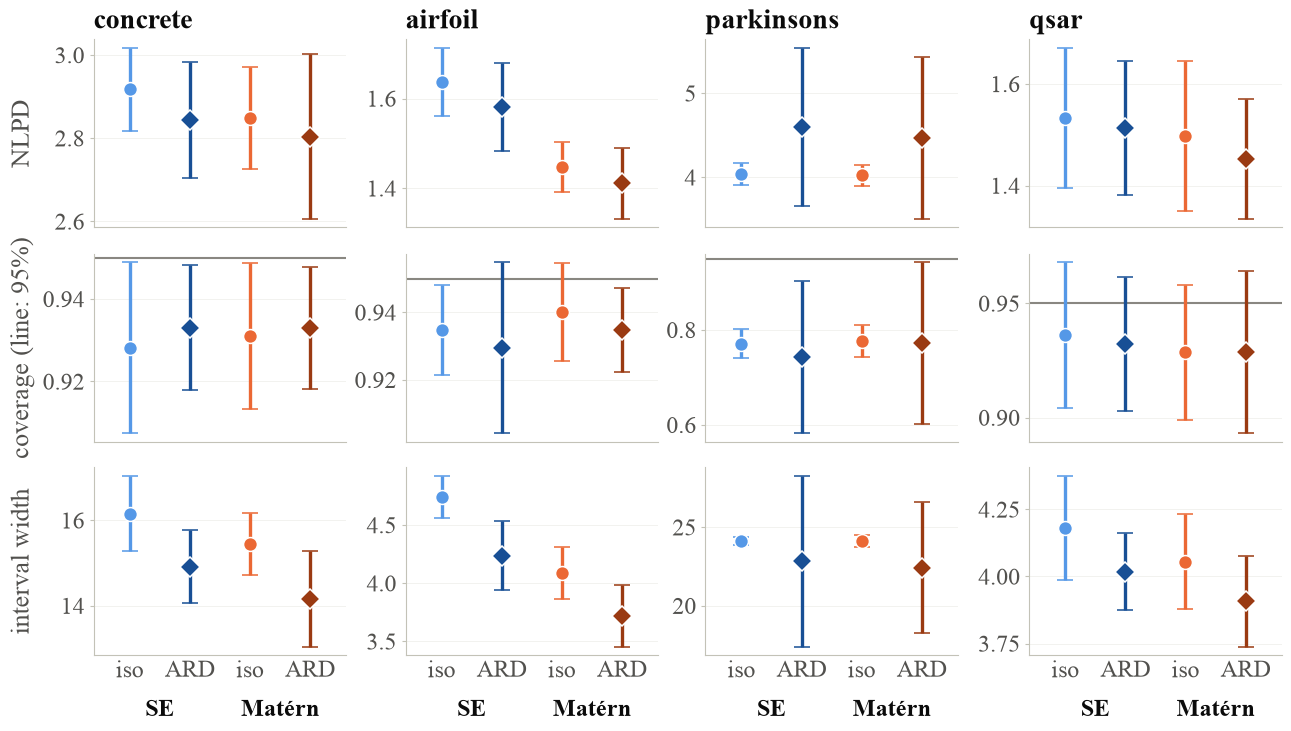

In [12]:
Analysis.plot_metrics(runs, ["nlpd", "coverage", "width"])

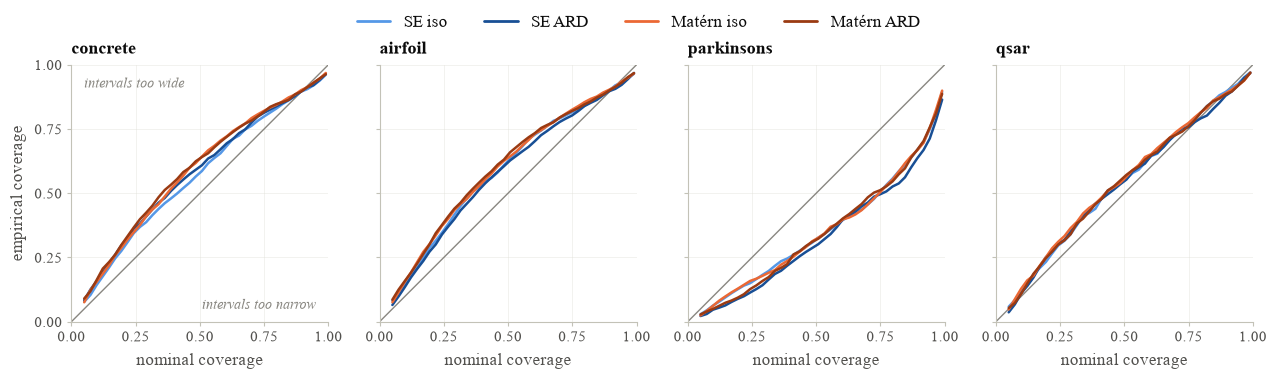

In [13]:
Analysis.plot_calibration(preds)

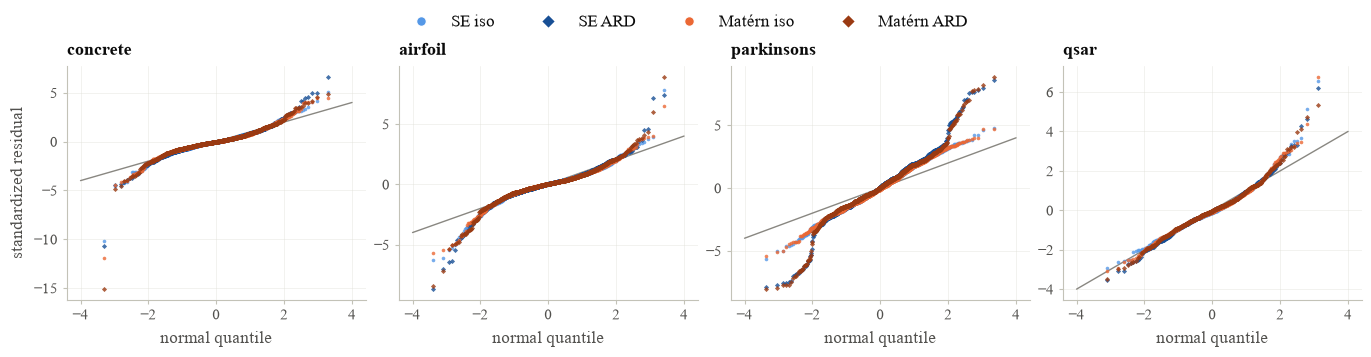

In [14]:
Analysis.plot_residuals(preds)

In [15]:
Analysis.residual_stats(preds)

sd  excess_kurtosis  beyond_2sd
dataset    model                                         
concrete   SE iso      1.099            8.939       0.071
           SE ARD      1.119           11.186       0.066
           Matérn iso  1.079           16.601       0.065
           Matérn ARD  1.128           32.967       0.062
airfoil    SE iso      1.054            6.198       0.061
           SE ARD      1.110            8.819       0.065
           Matérn iso  1.030            5.263       0.057
           Matérn ARD  1.085            9.939       0.061
parkinsons SE iso      1.619           -0.104       0.221
           SE ARD      2.029            2.641       0.248
           Matérn iso  1.612           -0.129       0.212
           Matérn ARD  1.964            3.267       0.220
qsar       SE iso      1.072            3.700       0.062
           SE ARD      1.098            2.852       0.066
           Matérn iso  1.073            3.691       0.066
           Matérn ARD  1.076            2.407       0.071

In [16]:
ranks, agreement = Analysis.selection(runs)
ranks

CV RMSE  CV NLPD  CV calibration error  max LML  \
dataset    model                                                         
concrete   SE iso          3.6      3.4                   1.4      4.0   
           SE ARD          3.2      2.8                   2.0      2.6   
           Matérn iso      2.0      2.2                   3.0      2.4   
           Matérn ARD      1.2      1.6                   3.6      1.0   
airfoil    SE iso          3.6      3.6                   2.0      4.0   
           SE ARD          3.4      3.4                   1.4      2.0   
           Matérn iso      1.8      1.8                   3.2      3.0   
           Matérn ARD      1.2      1.2                   3.4      1.0   
parkinsons SE iso          3.2      2.4                   2.0      4.0   
           SE ARD          2.8      3.6                   3.0      2.0   
           Matérn iso      2.6      1.8                   2.6      3.0   
           Matérn ARD      1.4      2.2                   2.4      1.0   
qsar       SE iso          3.2      3.8                   1.8      4.0   
           SE ARD          2.8      2.8                   3.0      2.0   
           Matérn iso      2.6      2.4                   2.6      3.0   
           Matérn ARD      1.4      1.0                   2.6      1.0   

                       min BIC  
dataset    model                
concrete   SE iso          3.8  
           SE ARD          3.2  
           Matérn iso      1.8  
           Matérn ARD      1.2  
airfoil    SE iso          4.0  
           SE ARD          2.0  
           Matérn iso      3.0  
           Matérn ARD      1.0  
parkinsons SE iso          4.0  
           SE ARD          2.0  
           Matérn iso      3.0  
           Matérn ARD      1.0  
qsar       SE iso          3.2  
           SE ARD          3.8  
           Matérn iso      1.0  
           Matérn ARD      2.0

In [17]:
agreement

,LML = CV RMSE,LML = CV NLPD,BIC = CV RMSE,BIC = CV NLPD
dataset,,,,
concrete,0.8,0.8,0.6,0.6
airfoil,0.8,0.8,0.8,0.8
parkinsons,0.8,0.4,0.8,0.4
qsar,0.8,1.0,0.0,0.0


In [18]:
Analysis.paired_tests(runs)

mean_diff  ci_low  ci_high wins  \
dataset    comparison              metric                                    
concrete   Matérn ARD − SE ARD     rmse       -0.370  -0.857    0.117  5/5   
                                   nlpd       -0.040  -0.172    0.092  4/5   
           Matérn iso − SE iso     rmse       -0.391  -0.656   -0.125  5/5   
                                   nlpd       -0.068  -0.158    0.022  5/5   
           SE ARD − SE iso         rmse       -0.241  -1.189    0.707  3/5   
                                   nlpd       -0.073  -0.265    0.118  3/5   
           Matérn ARD − Matérn iso rmse       -0.220  -0.866    0.426  4/5   
                                   nlpd       -0.045  -0.241    0.150  4/5   
airfoil    Matérn ARD − SE ARD     rmse       -0.206  -0.280   -0.133  5/5   
                                   nlpd       -0.171  -0.219   -0.123  5/5   
           Matérn iso − SE iso     rmse       -0.246  -0.379   -0.113  5/5   
                                   nlpd       -0.190  -0.237   -0.144  5/5   
           SE ARD − SE iso         rmse       -0.085  -0.287    0.118  3/5   
                                   nlpd       -0.055  -0.256    0.146  3/5   
           Matérn ARD − Matérn iso rmse       -0.045  -0.141    0.051  4/5   
                                   nlpd       -0.036  -0.195    0.123  4/5   
parkinsons Matérn ARD − SE ARD     rmse       -0.308  -1.300    0.684  5/5   
                                   nlpd       -0.132  -0.353    0.090  5/5   
           Matérn iso − SE iso     rmse       -0.062  -0.197    0.073  4/5   
                                   nlpd       -0.013  -0.072    0.047  4/5   
           SE ARD − SE iso         rmse       -0.510  -2.995    1.976  3/5   
                                   nlpd        0.562  -1.304    2.428  1/5   
           Matérn ARD − Matérn iso rmse       -0.756  -3.189    1.677  4/5   
                                   nlpd        0.443  -1.513    2.399  2/5   
qsar       Matérn ARD − SE ARD     rmse       -0.042  -0.097    0.013  5/5   
                                   nlpd       -0.060  -0.100   -0.020  5/5   
           Matérn iso − SE iso     rmse       -0.014  -0.065    0.036  3/5   
                                   nlpd       -0.036  -0.057   -0.015  5/5   
           SE ARD − SE iso         rmse        0.001  -0.077    0.079  4/5   
                                   nlpd       -0.021  -0.055    0.014  4/5   
           Matérn ARD − Matérn iso rmse       -0.026  -0.080    0.028  4/5   
                                   nlpd       -0.045  -0.105    0.015  5/5   

                                           p_corrected  
dataset    comparison              metric               
concrete   Matérn ARD − SE ARD     rmse      1.025e-01  
                                   nlpd      4.491e-01  
           Matérn iso − SE iso     rmse      1.499e-02  
                                   nlpd      1.040e-01  
           SE ARD − SE iso         rmse      5.196e-01  
                                   nlpd      3.475e-01  
           Matérn ARD − Matérn iso rmse      3.976e-01  
                                   nlpd      5.548e-01  
airfoil    Matérn ARD − SE ARD     rmse      1.475e-03  
                                   nlpd      5.749e-04  
           Matérn iso − SE iso     rmse      6.839e-03  
                                   nlpd      3.342e-04  
           SE ARD − SE iso         rmse      3.109e-01  
                                   nlpd      4.887e-01  
           Matérn ARD − Matérn iso rmse      2.607e-01  
                                   nlpd      5.656e-01  
parkinsons Matérn ARD − SE ARD     rmse      4.372e-01  
                                   nlpd      1.746e-01  
           Matérn iso − SE iso     rmse      2.742e-01  
                                   nlpd      5.908e-01  
           SE ARD − SE iso         rmse      5.997e-01  
                                   nlpd      4.500e-01  
           Matérn ARD 

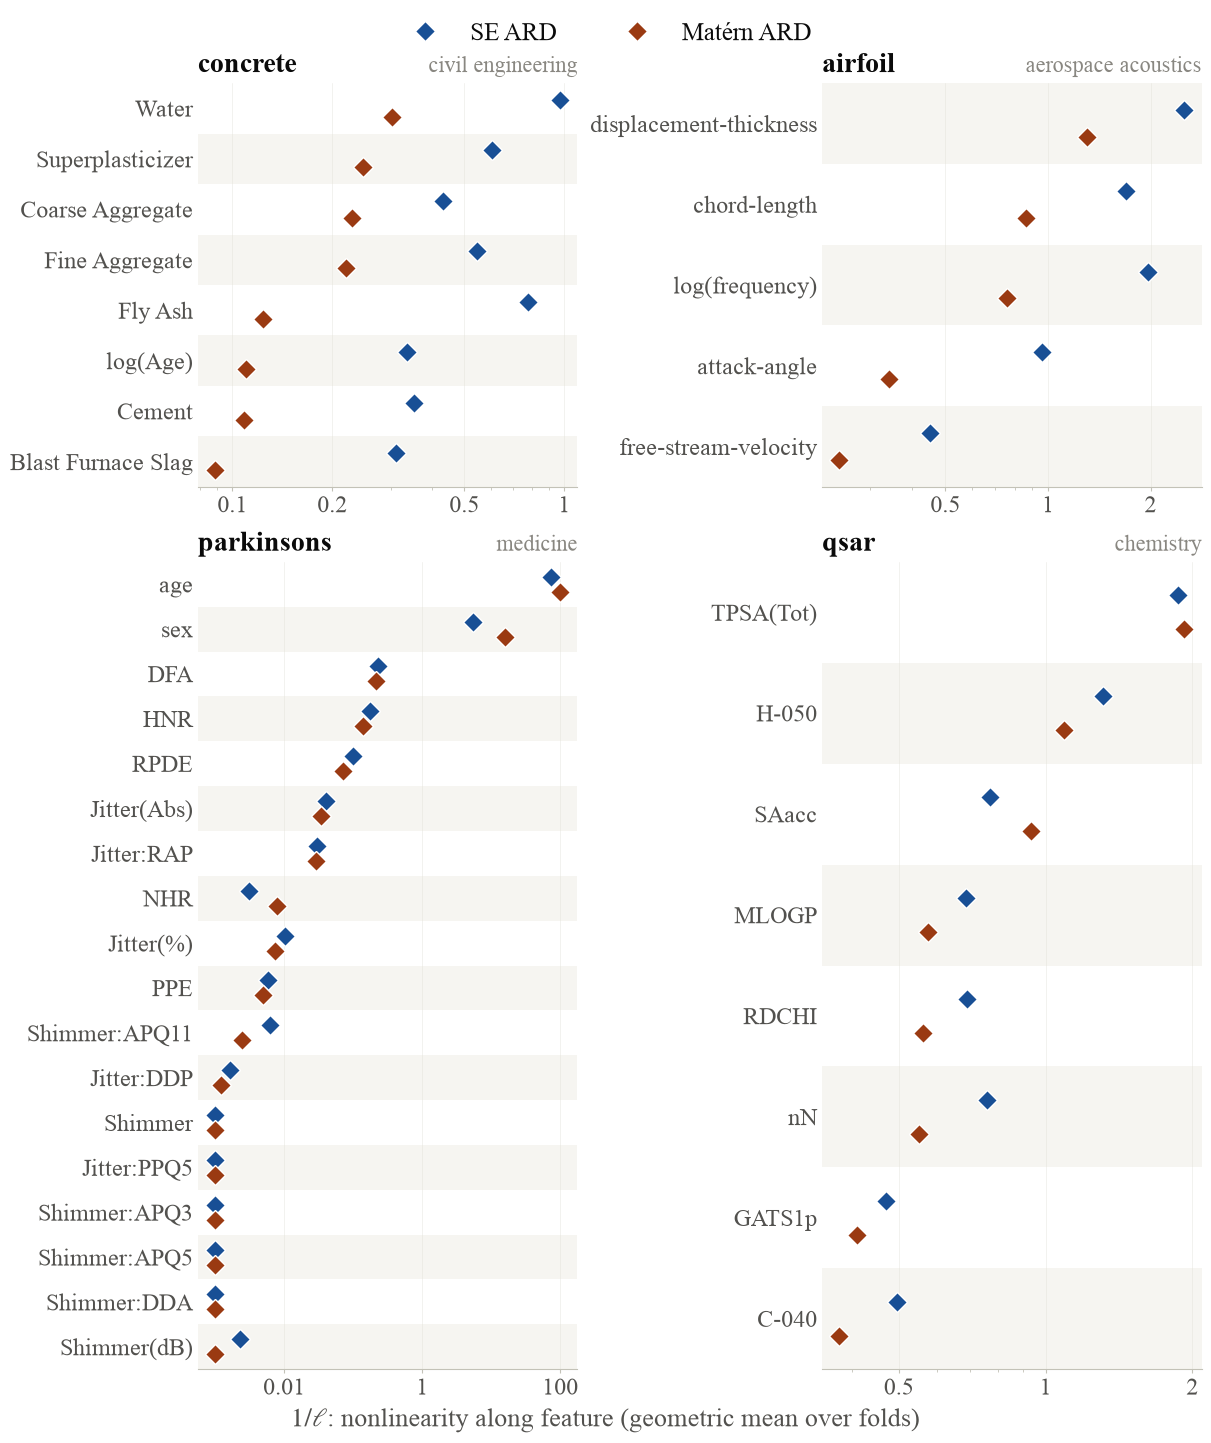

In [19]:
Analysis.plot_relevance(runs)

In [20]:
imp = Analysis.importance(runs)

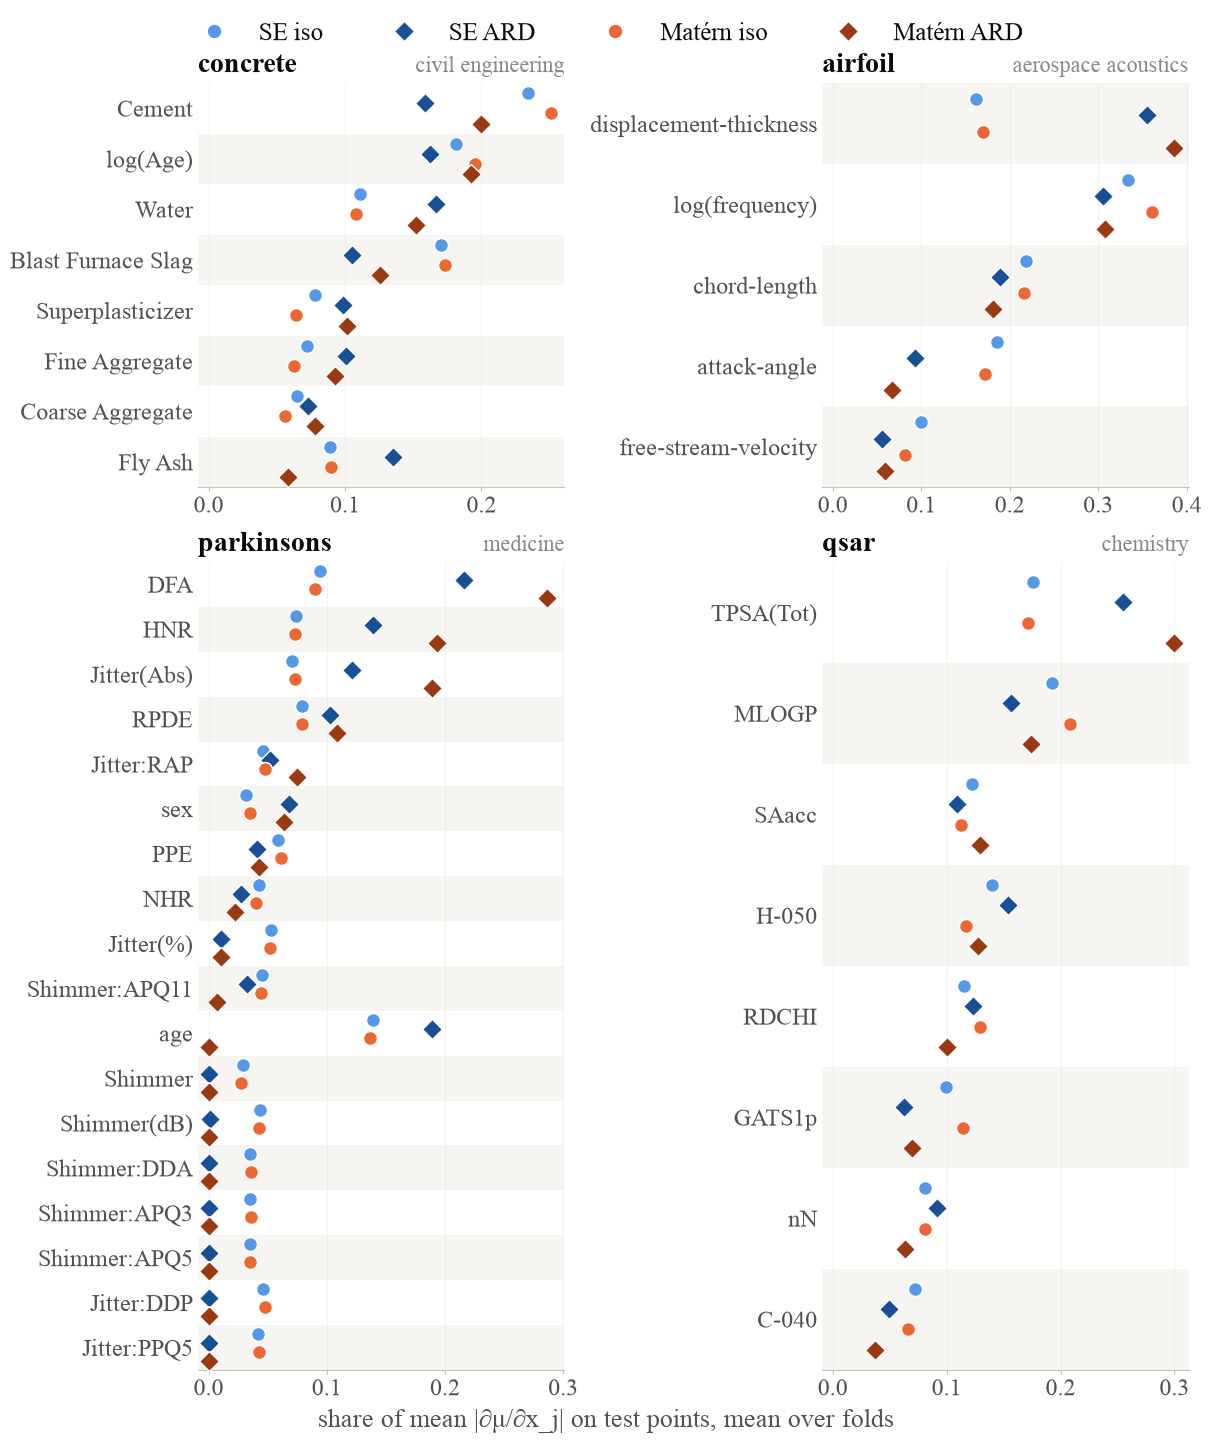

In [21]:
Analysis.plot_importance(imp)

In [22]:
Analysis.table(runs, ["signal_var", "noise_var", "unexplained"])

signal_var          noise_var      unexplained
dataset    model                                                         
concrete   SE iso         1.25 ± 0.19    0.0383 ± 0.0068   0.0871 ± 0.019
           SE ARD         1.54 ± 0.18      0.03 ± 0.0046   0.0781 ± 0.012
           Matérn iso     2.21 ± 0.41    0.0278 ± 0.0049   0.0736 ± 0.017
           Matérn ARD        5.02 ± 1     0.0228 ± 0.006    0.066 ± 0.011
airfoil    SE iso         0.92 ± 0.02    0.0152 ± 0.0011  0.0385 ± 0.0081
           SE ARD      0.953 ± 0.0093     0.0128 ± 0.002  0.0334 ± 0.0044
           Matérn iso    1.65 ± 0.037  0.00358 ± 0.00061  0.0256 ± 0.0048
           Matérn ARD    1.73 ± 0.091  0.00232 ± 0.00074  0.0235 ± 0.0046
parkinsons SE iso       0.679 ± 0.085      0.256 ± 0.039      1.54 ± 0.41
           SE ARD        0.918 ± 0.24    0.0902 ± 0.0051      1.34 ± 0.32
           Matérn iso      0.83 ± 0.1       0.16 ± 0.035      1.52 ± 0.42
           Matérn ARD   0.775 ± 0.059    0.0821 ± 0.0046      1.24 ± 0.25
qsar       SE iso         0.9 ± 0.055      0.265 ± 0.095     0.478 ± 0.08
           SE ARD        0.841 ± 0.04      0.199 ± 0.062    0.479 ± 0.069
           Matérn iso    0.96 ± 0.072      0.182 ± 0.063     0.465 ± 0.06
           Matérn ARD   0.903 ± 0.042      0.144 ± 0.044    0.443 ± 0.047

In [23]:
Analysis.winners(runs)

,field,CV RMSE,CV NLPD,CV calibration error,max LML,min BIC
dataset,,,,,,
concrete,civil engineering,Matérn ARD,Matérn ARD,SE iso,Matérn ARD,Matérn ARD
airfoil,aerospace acoustics,Matérn ARD,Matérn ARD,SE ARD,Matérn ARD,Matérn ARD
parkinsons,medicine,Matérn ARD,Matérn iso,SE iso,Matérn ARD,Matérn ARD
qsar,chemistry,Matérn ARD,Matérn ARD,SE iso,Matérn ARD,Matérn iso
